In [1]:
# Install necessary packages (if needed)
!pip install pandas numpy scikit-learn torch matplotlib

# Imports
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, r2_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import torch
import torch.nn as nn
import torch.utils.data as data
from torch.utils.data import DataLoader, TensorDataset

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 MB 24.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 42.4 MB/s eta 0:00:00
  Attempting uninstall: sympy
    Found existing installation: sympy 1.13.2
    Uninstalling sympy-1.13.2:━━━━━━━━━━━━━━━━━━ 0/2 [sympy]
      Successfully uninstalled sympy-1.13.2━━━━━ 0/2 [sympy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torch]32m1/2 [torch]


In [16]:
import os
import pandas as pd

# Change to your local MIMIC-III directory
os.chdir('/Users/led7283981/Downloads/mimic-iii-clinical-database-1.4')
base = os.getcwd()

# Load ADMISSIONS and PATIENTS tables (uncompressed CSVs)
adm = pd.read_csv(os.path.join(base, 'ADMISSIONS.csv'))
pat = pd.read_csv(os.path.join(base, 'PATIENTS.csv'))

# Merge subject demographics
df = adm.merge(pat[['SUBJECT_ID','DOB','GENDER']], on='SUBJECT_ID')

# Convert ADMITTIME and DOB to datetime formats
df['ADMITTIME'] = pd.to_datetime(df['ADMITTIME'])
df['DOB']      = pd.to_datetime(df['DOB'])

# Compute age at admission safely using year difference (avoids overflow)
df['age'] = df['ADMITTIME'].dt.year - df['DOB'].dt.year

# Binary in-hospital mortality label
labels = df['HOSPITAL_EXPIRE_FLAG']


# Downstream Task 1 - In-Hospital Mortality Prediction

In [17]:
# Example: one-hot encode ADMISSION_TYPE, GENDER
df = pd.get_dummies(df, columns=['ADMISSION_TYPE','GENDER'])
static_features = df[['age','ADMISSION_TYPE_EMERGENCY','GENDER_F','GENDER_M']]

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    static_features, labels, test_size=0.2, random_state=42)

In [19]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'RandomForest': RandomForestClassifier(n_estimators=100)
}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
    print(f"{name}: AUC={auc:.3f}, Accuracy={accuracy_score(y_test,preds):.3f}")

LogisticRegression: AUC=0.695, Accuracy=0.904
RandomForest: AUC=0.686, Accuracy=0.904


In [20]:
param_grid = {'n_estimators':[100,200], 'max_depth':[4,8]}
grid = GridSearchCV(RandomForestClassifier(), param_grid, cv=3)
grid.fit(X_train, y_train)
best = grid.best_estimator_
y_pred = best.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      1.00      0.95     10658
           1       0.00      0.00      0.00      1138

    accuracy                           0.90     11796
   macro avg       0.45      0.50      0.47     11796
weighted avg       0.82      0.90      0.86     11796



/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


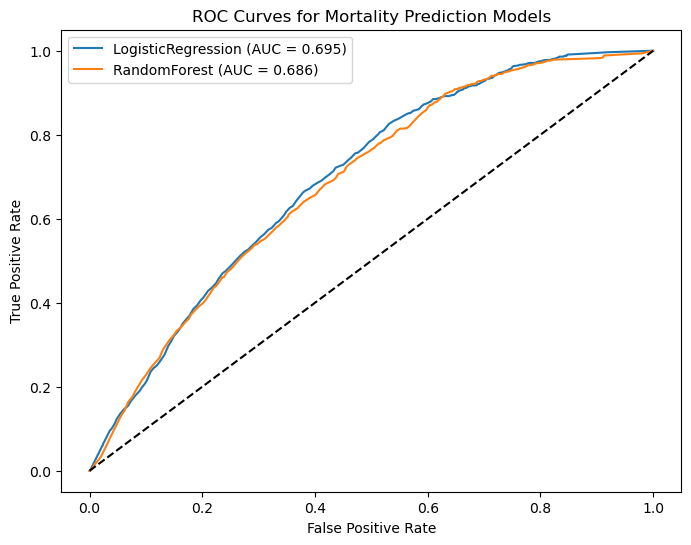

In [23]:
# ROC Curves for each model
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))
for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Mortality Prediction Models")
plt.legend()
plt.show()

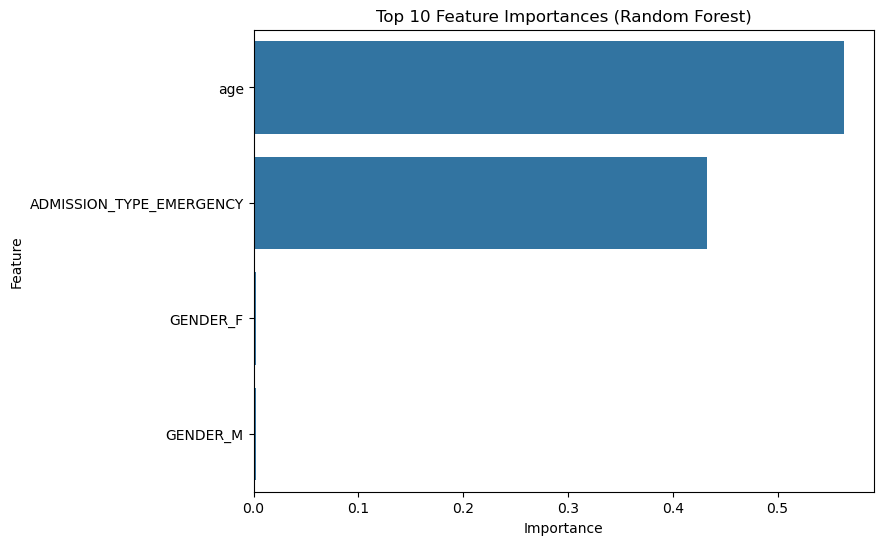

              precision    recall  f1-score   support

           0       0.90      1.00      0.95     10658
           1       0.00      0.00      0.00      1138

    accuracy                           0.90     11796
   macro avg       0.45      0.50      0.47     11796
weighted avg       0.82      0.90      0.86     11796



/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [24]:
# Feature importance for Random Forest
import seaborn as sns
import pandas as pd

importances = best.feature_importances_
feat_names = X_train.columns
feat_imp = pd.Series(importances, index=feat_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(8,6))
sns.barplot(x=feat_imp.values, y=feat_imp.index)
plt.title("Top 10 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

param_grid = {'n_estimators':[100,200], 'max_depth':[4,8]}
grid = GridSearchCV(RandomForestClassifier(), param_grid, cv=3)
grid.fit(X_train, y_train)
best = grid.best_estimator_
y_pred = best.predict(X_test)
print(classification_report(y_test, y_pred))

# Downstream Task 2 - Given the sequence of diagnosis-category IDs for a single hospital admission (in the order they occured), predict what the next diagnosis category will be.

In [76]:
import os
import numpy as np
import pandas as pd

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split

In [77]:
# These bins carve continuous ICD-9 codes into 18 broad ranges.
bins   = [0,140,240,280,290,320,390,460,520,580,630,680,710,740,760,780,800,1000,2000]
labels = list(range(len(bins) - 1))  # → [0,1,…,17], one label per bin


In [78]:
os.chdir('/Users/led7283981/Downloads/mimic-iii-clinical-database-1.4')
base_path = os.getcwd()
diag = pd.read_csv(os.path.join(base_path, 'DIAGNOSES_ICD.csv.gz'))

# Extract first three digits, replace non-numeric with 999, then map into our 18 bins
diag['code3'] = (
    diag['ICD9_CODE']
        .str.extract(r'(^\d{3})')[0]
        .fillna('999')
        .astype(int)
)
diag['cat'] = pd.cut(diag['code3'], bins=bins, labels=labels).astype(int)

In [79]:
# Sort so that SEQ_NUM gives the order within each admission
diag = diag.sort_values(['SUBJECT_ID', 'HADM_ID', 'SEQ_NUM'])

# Group by admission and collect the category sequence
seqs = diag.groupby('HADM_ID')['cat'].apply(list)

In [80]:
# Sort so that SEQ_NUM gives the order within each admission
diag = diag.sort_values(['SUBJECT_ID', 'HADM_ID', 'SEQ_NUM'])

# Group by admission and collect the category sequence
seqs = diag.groupby('HADM_ID')['cat'].apply(list)

In [81]:
# For each admission with ≥2 diagnoses:
#   - X = all categories except the last
#   - y = the final category
X_seqs = [s[:-1] for s in seqs if len(s) > 1]
y_cats = [s[-1]  for s in seqs if len(s) > 1]

In [82]:
# For each admission with ≥2 diagnoses:
#   - X = all categories except the last
#   - y = the final category
X_seqs = [s[:-1] for s in seqs if len(s) > 1]
y_cats = [s[-1]  for s in seqs if len(s) > 1]

In [83]:
maxlen = 50
X_pad = pad_sequences(
    X_seqs,
    maxlen=maxlen,
    padding='pre',      # pad at the front
    truncating='pre'    # if too long, keep the last 50
)

In [84]:
num_classes = len(labels)        # 18 categories
y_cat       = to_categorical(y_cats, num_classes=num_classes)

In [85]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pad, y_cat,
    test_size=0.2,
    random_state=0
)

In [86]:
model = Sequential([
    Embedding(input_dim=num_classes, output_dim=32, input_length=maxlen),
    LSTM(64),
    Dense(num_classes, activation='softmax')
])
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)
model.summary()

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [87]:
history = model.fit(
    X_train, y_train,
    validation_split=0.1,   # use 10% of train as a val set
    epochs=10,
    batch_size=128
)

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {acc:.4f}")

Epoch 1/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4254 - loss: 2.0980 - val_accuracy: 0.4397 - val_loss: 1.8668
Epoch 2/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.4411 - loss: 1.8644 - val_accuracy: 0.4433 - val_loss: 1.8453
Epoch 3/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.4434 - loss: 1.8423 - val_accuracy: 0.4502 - val_loss: 1.8303
Epoch 4/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.4441 - loss: 1.8391 - val_accuracy: 0.4414 - val_loss: 1.8289
Epoch 5/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4518 - loss: 1.8159 - val_accuracy: 0.4455 - val_loss: 1.8195
Epoch 6/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4525 - loss: 1.8035 - val_accuracy: 0.4465 - val_loss: 1.8166
Epoch 7/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4469 - loss: 1.8186 - val_accuracy: 0.4502 - val_loss: 1.8105
Epoch 8/10
330/330 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4460 - loss: 1.8097 - val_accu

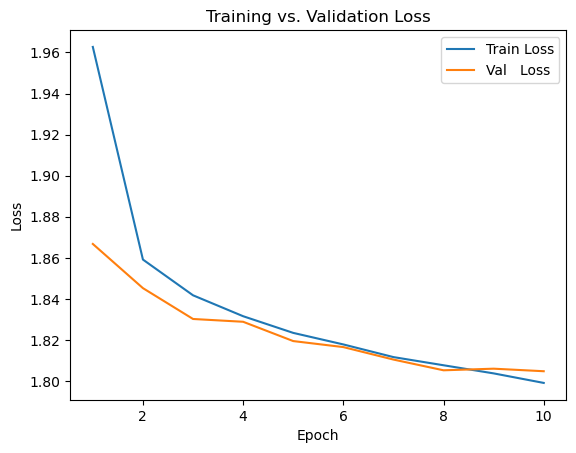

In [88]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
# 1) Training & Validation Loss curve
epochs = range(1, len(history.history['loss']) + 1)
plt.figure()
plt.plot(epochs, history.history['loss'], label='Train Loss')
plt.plot(epochs, history.history['val_loss'], label='Val   Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs. Validation Loss')
plt.legend()
plt.show()

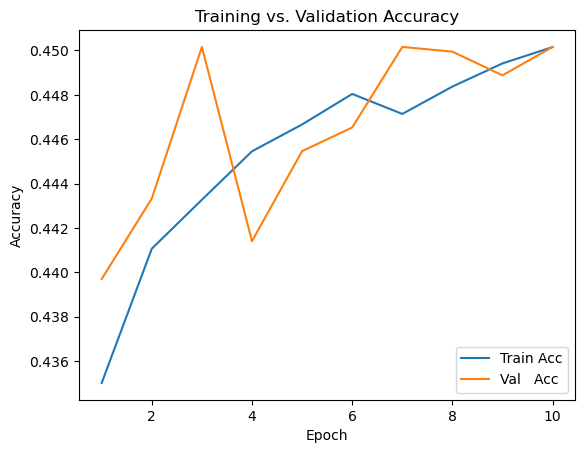

In [89]:
# 2) Training & Validation Accuracy curve
plt.figure()
plt.plot(epochs, history.history['accuracy'], label='Train Acc')
plt.plot(epochs, history.history['val_accuracy'], label='Val   Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs. Validation Accuracy')
plt.legend()
plt.show()

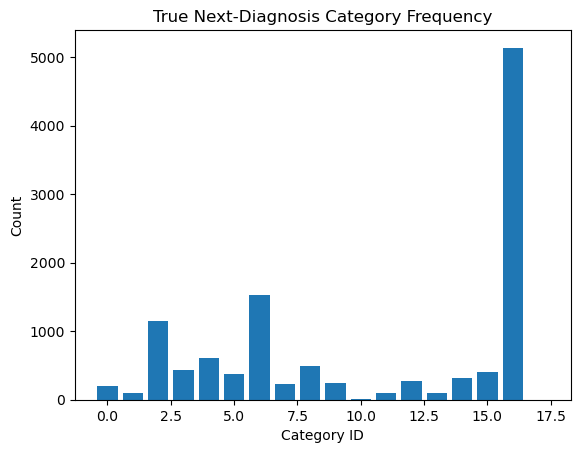

In [90]:
# 3) Next‐Category Distribution in Test Set
#    (how often each category appears as the ground truth in X_test → y_test)
counts = y_test.sum(axis=0)
plt.figure()
plt.bar(range(num_classes), counts)
plt.xlabel('Category ID')
plt.ylabel('Count')
plt.title('True Next‐Diagnosis Category Frequency')
plt.show()

366/366 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


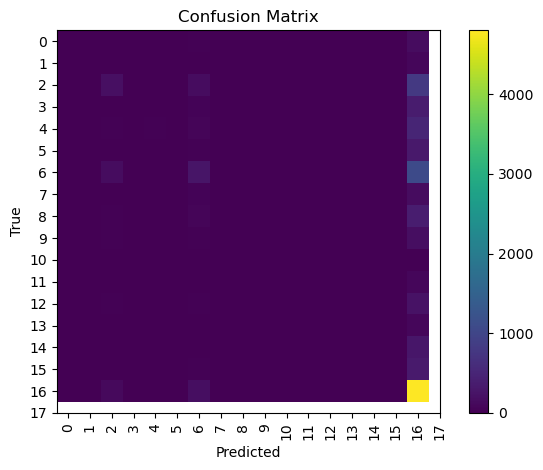

In [91]:
# 4) Confusion Matrix on the Test Set
y_pred_probs = model.predict(X_test)
y_pred = y_pred_probs.argmax(axis=1)
y_true = y_test.argmax(axis=1)
cm = confusion_matrix(y_true, y_pred)

plt.figure()
plt.imshow(cm, interpolation='nearest')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.colorbar()
plt.xticks(range(num_classes), range(num_classes), rotation=90)
plt.yticks(range(num_classes), range(num_classes))
plt.tight_layout()
plt.show()